Matriz de Sustentación (N):
 [[  38.48   68.42  106.90  153.94  209.53]
 [  76.97  136.83  213.80  307.88  419.05]
 [ 115.45  205.25  320.70  461.81  628.58]
 [ 153.94  273.67  427.61  615.75  838.11]
 [ 192.42  342.08  534.51  769.69 1047.63]]
Matriz de Resistencia (N):
 [[  3.85   6.84  10.69  15.39  20.95]
 [  7.70  13.68  21.38  30.79  41.91]
 [ 11.55  20.53  32.07  46.18  62.86]
 [ 15.39  27.37  42.76  61.58  83.81]
 [ 19.24  34.21  53.45  76.97 104.76]]


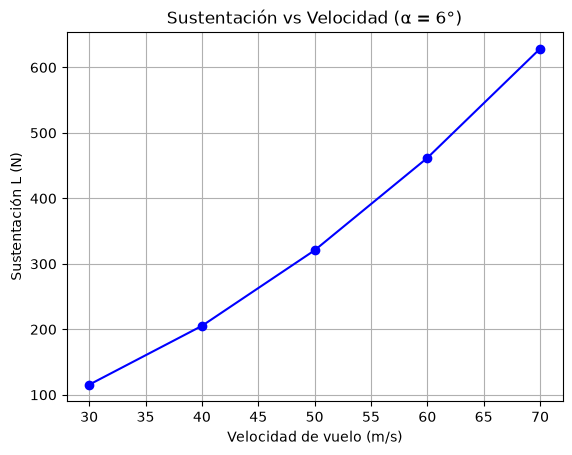

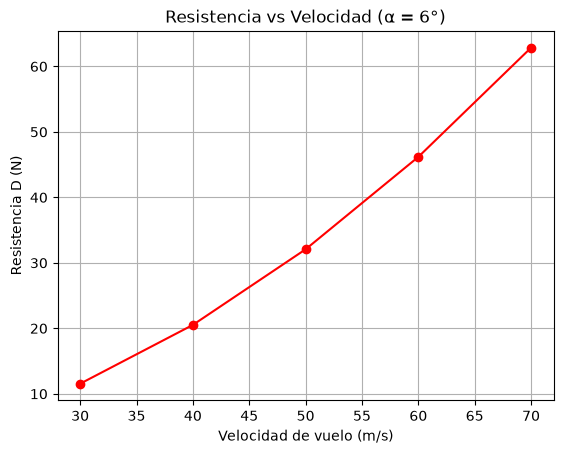

In [1]:
#Tarea 2:
# Importo las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt

# Defino las clases necesarias para el cálculo de fuerzas aerodinámicas
class PerfilAlar:
    def __init__(self, cl_alpha, cd_alpha):
        self.cl_alpha = cl_alpha
        self.cd_alpha = cd_alpha

    def coeficientes(self, alpha_rad):
        cl = self.cl_alpha * alpha_rad
        cd = self.cd_alpha * alpha_rad
        return cl, cd

# Defino la clase para las condiciones de vuelo
class CondicionesVuelo:
    def __init__(self, rho, S_w, alphas_deg, velocidades):
        self.rho = rho
        self.S_w = S_w
        # Convertimos lista de ángulos de grados a radianes
        self.alphas_rad = np.deg2rad(alphas_deg)
        self.velocidades = velocidades

# Defino la clase principal para el cálculo de fuerzas aerodinámicas
class Aerodinamica:
    def __init__(self, perfil, condiciones):
        self.perfil = perfil
        self.condiciones = condiciones

# Defino el método para calcular las matrices de fuerzas L y D
    def matriz_fuerzas(self):
        """
        Devuelve matrices de sustentación y resistencia
        para todas las combinaciones de ángulo y velocidad.
        """
        L_matrix = np.zeros((len(self.condiciones.alphas_rad),
                             len(self.condiciones.velocidades)))
        D_matrix = np.zeros_like(L_matrix)
# Calculamos las fuerzas para cada combinación de ángulo y velocidad
        for i, alpha in enumerate(self.condiciones.alphas_rad):
            cl, cd = self.perfil.coeficientes(alpha)
            for j, V in enumerate(self.condiciones.velocidades):
                q = 0.5 * self.condiciones.rho * V**2
                L_matrix[i, j] = q * self.condiciones.S_w * cl
                D_matrix[i, j] = q * self.condiciones.S_w * cd

        return L_matrix, D_matrix
    
# Defino los métodos para graficar sustentación y resistencia
    def grafico_sustentacion(self, alpha_deg):
        """
        Gráfico de sustentación vs velocidad para un ángulo dado.
        """
        alpha_rad = np.deg2rad(alpha_deg)
        cl, _ = self.perfil.coeficientes(alpha_rad)
        L_vals = [0.5 * self.condiciones.rho * V**2 *
                  self.condiciones.S_w * cl for V in self.condiciones.velocidades]
        
# Generamos el gráfico de sustentación
        plt.plot(self.condiciones.velocidades, L_vals, 'b-o')
        plt.xlabel("Velocidad de vuelo (m/s)")
        plt.ylabel("Sustentación L (N)")
        plt.title(f"Sustentación vs Velocidad (α = {alpha_deg}°)")
        plt.grid(True)
        plt.show()

# Defino el método para graficar resistencia
    def grafico_resistencia(self, alpha_deg):
        """
        Gráfico de resistencia vs velocidad para un ángulo dado.
        """
        alpha_rad = np.deg2rad(alpha_deg)
        _, cd = self.perfil.coeficientes(alpha_rad)
        D_vals = [0.5 * self.condiciones.rho * V**2 *
                  self.condiciones.S_w * cd for V in self.condiciones.velocidades]
        
# Generamos el gráfico de resistencia
        plt.plot(self.condiciones.velocidades, D_vals, 'r-o')
        plt.xlabel("Velocidad de vuelo (m/s)")
        plt.ylabel("Resistencia D (N)")
        plt.title(f"Resistencia vs Velocidad (α = {alpha_deg}°)")
        plt.grid(True)
        plt.show()

# Ejemplo de ejecución
# Defino los parámetros del perfil alar y las condiciones de vuelo
cl_alpha = 0.1
cd_alpha = 0.01
rho = 1.225
S_w = 20.0
alphas_deg = [2, 4, 6, 8, 10]        # lista de ángulos en grados
velocidades = [30, 40, 50, 60, 70]   # lista de velocidades en m/s
# Creamos instancias de las clases y calculamos las matrices de fuerzas
perfil = PerfilAlar(cl_alpha, cd_alpha)
condiciones = CondicionesVuelo(rho, S_w, alphas_deg, velocidades)
aero = Aerodinamica(perfil, condiciones)
np.set_printoptions(precision=2, floatmode='fixed')
L_matrix, D_matrix = aero.matriz_fuerzas()
print("Matriz de Sustentación (N):\n", L_matrix)
print("Matriz de Resistencia (N):\n", D_matrix)

# Gráficos para un ángulo elegido
aero.grafico_sustentacion(alpha_deg=6)
aero.grafico_resistencia(alpha_deg=6)
